# 02 · The same question on real electricity data, under a protocol written first

**Block 5 · W44, notebook 2 of 2.** Notebook 1 showed that on simulated data the freshness budget depends on the
served quantile by a factor of about 2, not 7. Simulations answer what they were built to answer, so here is the
same question on 314 real hourly load series, with the rules fixed **before** looking at any result.

| § | Question | Short answer |
|---|---|---|
| 1 | What did we commit to before running? | A protocol: data, model, cadences, metrics and a decision rule. |
| 2 | Is the data what we think it is? | 321 series, no gaps, no negatives; 7 excluded for too many zeros. |
| 3 | What do these series look like? | A strong daily cycle; a weekly one for a sixth of the series only. |
| 4 | Does the model beat the naive, and up to which cadence? | Never against the plan's naive; up to a month against the fair one. |
| 5 | What does the pre-registered rule conclude? | NEITHER. The fair-baseline variant, a deviation, gives CONTRADICTED. |
| 6 | How solid is a freshness budget measured this way? | Fragile: shifting the refit calendar changes it by a factor 2. |
| 7 | Coverage and stability? | 0.91 coverage for a 0.95 quantile; the stability clause depends on the method. |

> **How to read this notebook.** Callouts follow a fixed code:
> **Intuition**, the idea without equations · **Example**, a worked number ·
> **Watch out**, the trap to avoid · **Takeaway**, the memo to keep.

The heavy computation (12 model runs over 8,760 origins, about 4 minutes) is done once by `uv run w44 real run`
and cached in `data/results/`; this notebook reads the cache, except in section 6 which re-runs one variant.

In [1]:

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

from w44_retraining import realdata, viz
from w44_retraining.freshness import TAUS

viz.setup()
export = viz.exporter("../figures")


def show(headers, rows):
    """Render a small table as Markdown (no pandas dependency)."""
    lines = ["| " + " | ".join(map(str, headers)) + " |", "|" + "---|" * len(headers)]
    lines += ["| " + " | ".join(map(str, r)) + " |" for r in rows]
    display(Markdown("\n".join(lines)))


cfg = realdata.protocol()
out = realdata.study_cached()

## 1. The protocol, committed before any result

**Question.** Why write the rules down first?

> **Intuition.** With six cadences, two quantile methods, three baselines and four quarters there are dozens of
> ways to slice a result. If the reading is chosen after seeing the numbers, some slice will confirm whatever we
> hoped. Writing the decision rule first (and committing it to git with its own commit) removes that freedom.

The protocol is `configs/freshness_real.yaml`. Its key fields:

In [2]:
show(["field", "value"], [
    ("dataset", f"{cfg['dataset']['name']} ({cfg['dataset']['licence']}), {cfg['dataset']['series_expected']} series"),
    ("sha256 of the zip", cfg["dataset"]["sha256_zip"][:16] + "..."),
    ("evaluation", f"last {cfg['span']['evaluation_hours']} hours, {cfg['span']['history_before_evaluation']} h of history"),
    ("model", f"window {cfg['model']['window_w']} h, daily profile, horizon {cfg['model']['horizon_h']} h, "
              f"closing lag {cfg['model']['closing_lag_d']} h"),
    ("cadences k", ", ".join(map(str, cfg["cadences_k"]))),
    ("quantiles", ", ".join(map(str, cfg["quantiles"]["taus"])) + " (gaussian and conformal)"),
    ("k_max", cfg["metrics"]["k_max"]),
])
display(Markdown("**Decision rule, verbatim:** " + cfg["decision_rule"]))

| field | value |
|---|---|
| dataset | Monash Electricity Hourly (CC-BY-4.0), 321 series |
| sha256 of the zip | eff447075dde68dc... |
| evaluation | last 8760 hours, 552 h of history |
| model | window 240 h, daily profile, horizon 24 h, closing lag 48 h |
| cadences k | 1, 24, 72, 168, 336, 720 |
| quantiles | 0.5, 0.8, 0.95 (gaussian and conformal) |
| k_max | largest k in cadences_k whose scaled pinball is below seasonal_naive_24, per tau and method |

**Decision rule, verbatim:** The plan's claim ("the freshness budget is a function of the served quantile, k_max(0.50) / k_max(0.95) = 7") is supported on this dataset if, with conformal quantiles, k_max(0.50) / k_max(0.95) >= 4 on the full year and in at least 3 quarters out of 4. It is contradicted if the ratio is <= 1 on the full year.


> **Watch out.** The rule names `seasonal_naive_24`, the plan's baseline. When the protocol was written, the leak
> of that baseline (notebook 1, section 4) had not been found yet on this data path. We keep the rule as written
> and report the fair baseline separately, as a deviation. Changing the rule after the fact would undo the point
> of writing it.

## 2. Data checks, run at every load

Each check names the series and the count when it fails: same length and start for all series, no missing
value, no negative value, and the zip's sha256 must match the protocol. A series is excluded if more than 10% of
its evaluation span is exactly zero (a meter that is off, or a client not yet connected).

In [3]:
y, names, rep = realdata.load(cfg)
print(f"{rep['n_series']} series x {rep['T_file']} hours from {rep['start']}; kept the last {rep['T_kept']} hours")
show(["excluded series", "share of zeros in the evaluation year"], [(nm, f"{z:.0%}") for nm, z in rep["excluded"]])
print(f"evaluated: {y.shape[0]} series")

321 series x 26304 hours from 2012-01-01 00-00-01; kept the last 9336 hours


| excluded series | share of zeros in the evaluation year |
|---|---|
| T58 | 20% |
| T106 | 54% |
| T107 | 45% |
| T108 | 47% |
| T183 | 100% |
| T299 | 41% |
| T300 | 49% |

evaluated: 314 series


## 3. What the series look like

**Question.** What does the model have to capture?

Below, the **average week**: for each series, the mean load at each hour of the week over the evaluation year,
divided by the series' mean, then the median across the 314 series (line) and the middle half (band). The file
starts on Sunday 1 January 2012 at 00:00, so the hour of the week of any index is its position modulo 168; the
evaluation starts on Tuesday 31 December 2013 (hour 48 of the week). The served model is a 240-hour mean plus a
**24-hour** profile.

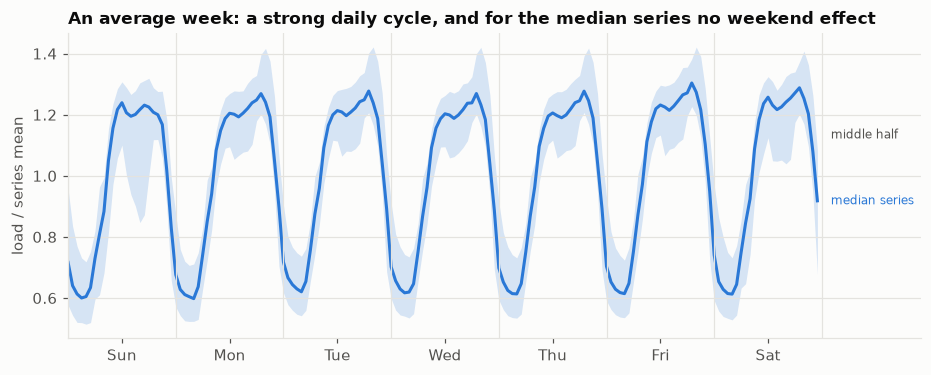

In [4]:
start = cfg["span"]["history_before_evaluation"]
week = realdata.weekly_profile(y, rep, cfg)
med, lo, hi = np.median(week, axis=0), np.percentile(week, 25, axis=0), np.percentile(week, 75, axis=0)
fig, ax = plt.subplots(figsize=(10, 3.6))
hours = np.arange(168)
ax.fill_between(hours, lo, hi, color=viz.BLUE, alpha=0.18, lw=0)
ax.plot(hours, med, color=viz.BLUE)
ax.text(170, med[-1], "median series", color=viz.BLUE, fontsize=8, va="center")
ax.text(170, hi[-1] + 0.05, "middle half", color=viz.TEXT_2, fontsize=8, va="center")
ax.set_xticks(np.arange(0, 168, 24) + 12, ["Sun", "Mon", "Tue", "Wed", "Thu", "Fri", "Sat"])
for d in range(0, 169, 24):
    ax.axvline(d, color=viz.GRID, lw=0.8)
ax.grid(axis="x", visible=False); ax.set_xlim(0, 190)
ax.set_ylabel("load / series mean")
ax.set_title("An average week: a strong daily cycle, and for the median series no weekend effect")
export(fig, "electricity_average_week"); plt.show()

The median series looks the same on Sunday as on Wednesday. The band, though, dips on Sunday daytime: *some*
series do have a weekend. How many, and do they matter? For each series, the ratio of its mean weekend load to
its mean weekday load:

In [5]:
ratio = realdata.weekend_ratio(week)
print("weekend / weekday ratio, percentiles 5, 25, 50, 75, 95:", np.round(np.percentile(ratio, [5, 25, 50, 75, 95]), 3))
groups = (("weekend >= 10% lower", ratio < 0.9), ("flat week (within 10%)", (ratio >= 0.9) & (ratio < 1.1)),
          ("weekend >= 10% higher", ratio >= 1.1))
show(["group", "series", "share"], [(g, int(m.sum()), f"{m.mean():.0%}") for g, m in groups])

weekend / weekday ratio, percentiles 5, 25, 50, 75, 95: [0.565 0.976 1.011 1.027 1.081]


| group | series | share |
|---|---|---|
| weekend >= 10% lower | 52 | 17% |
| flat week (within 10%) | 251 | 80% |
| weekend >= 10% higher | 11 | 4% |

**Question.** Does the weekly structure of that minority explain why the weekly naive (same hour last week) beats
the lag-72 naive (same hour three days ago), although it reads older data? Both are run per series, at the median.

| group | series | pinball of the weekly naive vs the lag-72 naive |
|---|---|---|
| weekend >= 10% lower | 52 | -45% |
| flat week (within 10%) | 251 | -4% |
| weekend >= 10% higher | 11 | -31% |

correlation between the weekend ratio and the gain: -0.64


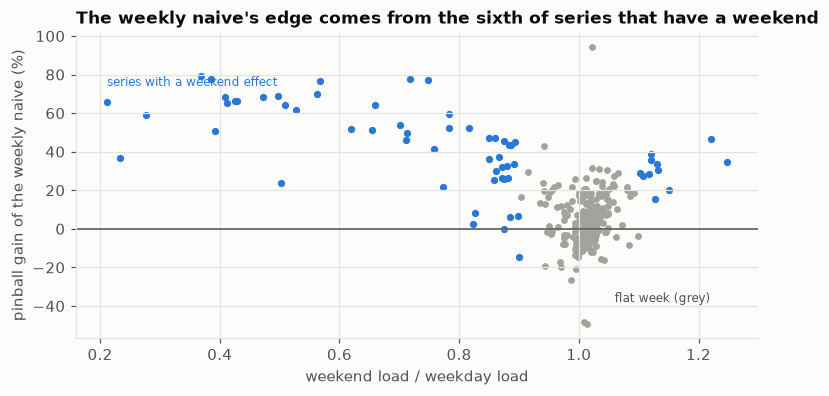

In [6]:
from w44_retraining.freshness import seasonal_naive  # noqa: E402

ev = y[:, start:]
scale = np.abs(ev[:, 24:] - ev[:, :-24]).mean(axis=1)
l72 = seasonal_naive(y, start=start, stop=y.shape[1], lag=72)["loss"][0.5] / scale
l168 = seasonal_naive(y, start=start, stop=y.shape[1], lag=168)["loss"][0.5] / scale
gain = 1 - l168 / l72
show(["group", "series", "pinball of the weekly naive vs the lag-72 naive"],
     [(g, int(m.sum()), f"{-gain[m].mean():+.0%}") for g, m in groups])
print(f"correlation between the weekend ratio and the gain: {np.corrcoef(ratio, gain)[0, 1]:+.2f}")

fig, ax = plt.subplots(figsize=(8, 3.6))
flat = (ratio >= 0.9) & (ratio < 1.1)
ax.scatter(ratio[flat], 100 * gain[flat], s=12, color=viz.MUTED)
ax.scatter(ratio[~flat], 100 * gain[~flat], s=14, color=viz.BLUE)
ax.axhline(0, color=viz.TEXT_2, lw=1)
ax.text(1.06, -38, "flat week (grey)", color=viz.TEXT_2, fontsize=8)
ax.text(ratio.min(), 100 * gain[~flat].max(), "series with a weekend effect", color=viz.BLUE, fontsize=8, va="top")
ax.set_xlabel("weekend load / weekday load"); ax.set_ylabel("pinball gain of the weekly naive (%)")
ax.set_title("The weekly naive's edge comes from the sixth of series that have a weekend")
export(fig, "weekly_naive_gain_vs_weekend"); plt.show()

> **Intuition.** A naive that copies last week gets every Sunday right for a client that closes on Sundays; a naive
> that copies three days ago predicts Sunday with Thursday. For the 80% of series whose week is flat, the two are
> nearly equivalent; for the 17% with a weekend dip the weekly naive is about twice as good. The served model, with
> a 24-hour profile, has the same blind spot as the lag-72 naive on that minority.

## 4. Scores per cadence, against three baselines

Scores are pinball losses divided by each series' own scale (its mean absolute day-over-day change), then
averaged over series, so a big industrial client does not dominate a small one. Three baselines:

- **naive lag 24**, the plan's: same hour yesterday, which reads actuals that are not closed under a 48-hour lag;
- **naive lag 72**: same hour three days ago, the newest value it reads is closed (the fair one);
- **naive lag 168**: same hour last week, closed too, and aware of the weekly cycle.

In [7]:
b = out["base"]
show(["baseline", *[f"tau={t:.2f}" for t in TAUS], "coverage 0.95"],
     [(nm, *(f"{b[key]['full'][t]:.4f}" for t in TAUS), f"{b[key]['cov'][0.95]:.3f}")
      for key, nm in (("snaive", "naive lag 24 (plan)"), ("snaive_closed", "naive lag 72 (closed)"),
                      ("snaive_168", "naive lag 168 (closed, weekly)"))])
ks = cfg["cadences_k"]
show(["k", *[f"{m} tau={t:.2f}" for m in ("gaussian", "conformal") for t in TAUS]],
     [(k, *(f"{out['model'][m, k]['full'][t]:.4f}" for m in ("gaussian", "conformal") for t in TAUS)) for k in ks])

| baseline | tau=0.50 | tau=0.80 | tau=0.95 | coverage 0.95 |
|---|---|---|---|---|
| naive lag 24 (plan) | 0.5001 | 0.4269 | 0.1941 | 0.945 |
| naive lag 72 (closed) | 0.6410 | 0.5303 | 0.2343 | 0.938 |
| naive lag 168 (closed, weekly) | 0.5586 | 0.4654 | 0.2190 | 0.932 |

| k | gaussian tau=0.50 | gaussian tau=0.80 | gaussian tau=0.95 | conformal tau=0.50 | conformal tau=0.80 | conformal tau=0.95 |
|---|---|---|---|---|---|---|
| 1 | 0.5461 | 0.4289 | 0.2054 | 0.5932 | 0.4713 | 0.2175 |
| 24 | 0.5492 | 0.4322 | 0.2082 | 0.5980 | 0.4753 | 0.2197 |
| 72 | 0.5528 | 0.4370 | 0.2124 | 0.6035 | 0.4798 | 0.2221 |
| 168 | 0.5755 | 0.4603 | 0.2331 | 0.6212 | 0.4904 | 0.2256 |
| 336 | 0.6001 | 0.4790 | 0.2462 | 0.6310 | 0.4958 | 0.2281 |
| 720 | 0.6294 | 0.4900 | 0.2442 | 0.6334 | 0.4877 | 0.2208 |

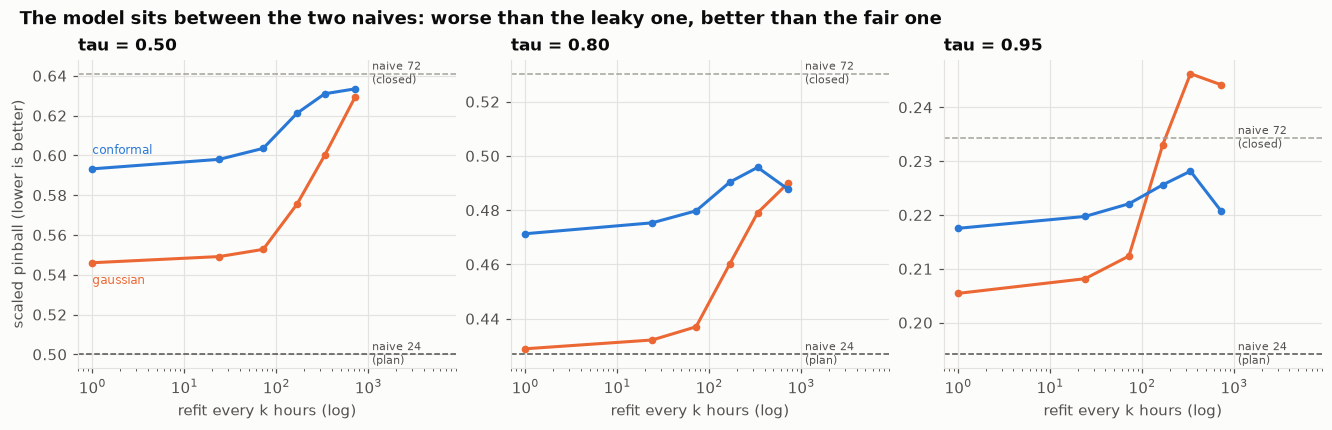

In [8]:
fig, axs = plt.subplots(1, 3, figsize=(12, 3.8), layout="constrained", sharex=True)
for ax, t in zip(axs, TAUS, strict=True):
    for m, c in (("gaussian", viz.ORANGE), ("conformal", viz.BLUE)):
        v = [out["model"][m, k]["full"][t] for k in ks]
        ax.plot(ks, v, color=c, marker="o", ms=4)
        if t == TAUS[0]:
            ax.text(1, v[0] + (0.006 if m == "conformal" else -0.006), m, color=c, fontsize=8,
                    va="bottom" if m == "conformal" else "top")
    for key, lab in (("snaive", "naive 24\n(plan)"), ("snaive_closed", "naive 72\n(closed)")):
        ax.axhline(b[key]["full"][t], color=viz.TEXT_2 if key == "snaive" else viz.MUTED, ls="--", lw=1)
        ax.text(1100, b[key]["full"][t], lab, color=viz.TEXT_2, fontsize=7, va="center")
    ax.set_xscale("log"); ax.set_xlim(0.7, 9000); ax.set_title(f"tau = {t:.2f}")
    ax.set_xlabel("refit every k hours (log)")
axs[0].set_ylabel("scaled pinball (lower is better)")
fig.suptitle("The model sits between the two naives: worse than the leaky one, better than the fair one",
             x=0.01, ha="left", fontweight="bold")
export(fig, "real_pinball_vs_cadence"); plt.show()

> **Example.** At the median, the gaussian model refit every hour scores 0.5461. The plan's naive scores 0.5001:
> it wins by reading the 48 freshest hours. The fair naive scores 0.6410: the model beats it by 15%. Same model,
> same data, opposite conclusions, decided entirely by which data the baseline is allowed to read.

> **Watch out.** The weekly naive (0.5586 at the median) nearly matches the model refit every hour (0.5461),
> and section 3 showed where its edge comes from: the sixth of series with a weekend effect. Adding a weekly
> profile for those series would likely move the score more than any cadence. The cadence question is
> second-order next to the model class.

## 5. The freshness budget, and the verdict

$k_{max}$ is the largest cadence whose score is still below the baseline, per quantile, on the full year and on
each quarter (2,190 hourly origins each).

In [9]:
rows = []
for (m, bn), v in out["k_max"].items():
    rows.append((m, "naive 24 (plan)" if bn == "snaive" else "naive 72 (closed)",
                 " / ".join(str(v["full"][t]) for t in TAUS),
                 *(" / ".join(str(q[t]) for t in TAUS) for q in v["quarters"])))
show(["quantiles", "baseline", "full year (0.50 / 0.80 / 0.95)", "Q1", "Q2", "Q3", "Q4"], rows)

| quantiles | baseline | full year (0.50 / 0.80 / 0.95) | Q1 | Q2 | Q3 | Q4 |
|---|---|---|---|---|---|---|
| gaussian | naive 24 (plan) | 0 / 0 / 0 | 0 / 336 / 168 | 0 / 0 / 0 | 0 / 0 / 0 | 0 / 168 / 72 |
| gaussian | naive 72 (closed) | 720 / 720 / 168 | 720 / 720 / 720 | 720 / 720 / 0 | 720 / 720 / 72 | 336 / 720 / 336 |
| conformal | naive 24 (plan) | 0 / 0 / 0 | 0 / 720 / 720 | 0 / 0 / 0 | 0 / 0 / 0 | 0 / 0 / 336 |
| conformal | naive 72 (closed) | 720 / 720 / 720 | 720 / 720 / 720 | 0 / 0 / 0 | 720 / 720 / 720 | 336 / 720 / 720 |

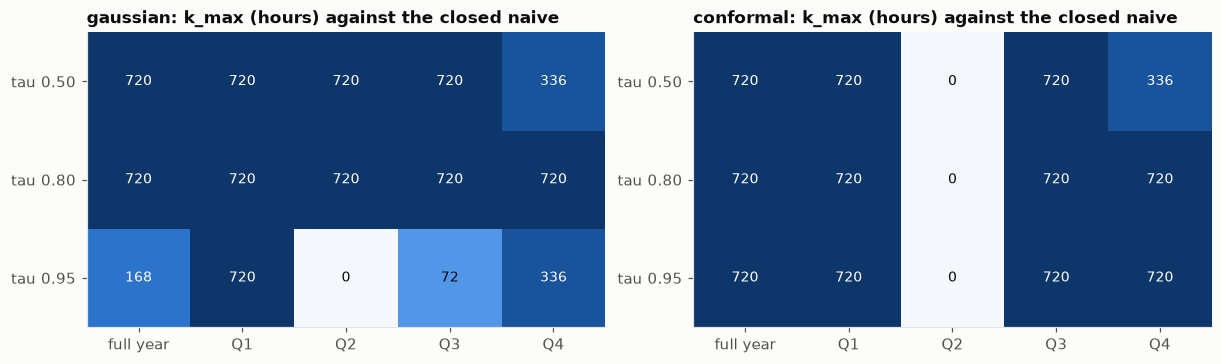

In [10]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.2), layout="constrained")
levels = [0, 1, 24, 72, 168, 336, 720]
for ax, m in zip(axs, ("gaussian", "conformal"), strict=True):
    v = out["k_max"][m, "snaive_closed"]
    grid = np.array([[v["full"][t] for t in TAUS]] + [[q[t] for t in TAUS] for q in v["quarters"]])
    im = ax.imshow(np.vectorize(levels.index)(grid).T, cmap=viz.SEQUENTIAL, vmin=0, vmax=len(levels) - 1,
                   aspect="auto")
    for (i, j), val in np.ndenumerate(grid):
        ax.text(i, j, str(val), ha="center", va="center", fontsize=9,
                color="white" if levels.index(val) >= 4 else viz.TEXT)
    ax.set_xticks(range(5), ["full year", "Q1", "Q2", "Q3", "Q4"])
    ax.set_yticks(range(3), [f"tau {t:.2f}" for t in TAUS]); ax.grid(False)
    ax.set_title(f"{m}: k_max (hours) against the closed naive")
export(fig, "real_kmax_by_quarter"); plt.show()

In [11]:
display(Markdown("**The decision rule, applied by the code:**\n\n```\n" + realdata.verdict(out) + "\n```"))

**The decision rule, applied by the code:**

```
   as written (seasonal_naive_24): ratio full year nan, quarters [nan, nan, nan, nan] -> NEITHER (undefined: the model never beats the baseline at the median)
   DEVIATION: closed naive lag 72, added after the protocol: ratio full year 1.0, quarters [1.0, nan, 1.0, 0.5] -> CONTRADICTED
```

**Reading the verdict honestly.**

- **As written**, the rule compares with the plan's naive. The model never beats it at the median, at any cadence,
  in any quarter, so $k_{max}(0.50) = 0$ and the ratio $k_{max}(0.50)/k_{max}(0.95)$ is undefined: **NEITHER**.
  That is the pre-registered answer.
- **Against the closed naive**, a deviation we report as such, conformal quantiles give 720 hours at every
  quantile: ratio 1.0, **CONTRADICTED**. The freshness budget does not depend on the quantile at all.

> **Takeaway.** On real load data, neither reading supports "the freshness budget is a function of the served
> quantile, with a factor 7". And Q2 (about April to June 2014) is a reminder that a year-level number hides
> three months where no cadence beats the fair naive with conformal quantiles.

## 6. How solid is a k_max? Shift the refit calendar

**Question.** If we start refitting on a different day, does the budget change?

The cached study starts the refit calendar 240 hours before the evaluation (to warm up the conformal errors). With
gaussian quantiles that warm-up changes nothing but *when* the refits happen. Below, the same gaussian runs with
the calendar starting at the evaluation instead (about 1.5 minutes).

In [12]:
shifted = realdata.gaussian_kmax_at_phase(y, cfg, warmup=0)
cached = out["k_max"]["gaussian", "snaive_closed"]["full"]
show(["refit calendar", *[f"k_max tau={t:.2f}" for t in TAUS], "ratio 0.50 / 0.95"],
     [("starts 240 h before (cached study)", *(cached[t] for t in TAUS), f"{cached[0.5] / cached[0.95]:.1f}"),
      ("starts with the evaluation", *(shifted["k_max"][t] for t in TAUS),
       f"{shifted['k_max'][0.5] / shifted['k_max'][0.95]:.1f}")])
show(["k", *[f"cached tau={t:.2f}" for t in TAUS], *[f"shifted tau={t:.2f}" for t in TAUS]],
     [(k, *(f"{out['model']['gaussian', k]['full'][t]:.4f}" for t in TAUS),
       *(f"{shifted['loss'][k][t]:.4f}" for t in TAUS)) for k in ks])

| refit calendar | k_max tau=0.50 | k_max tau=0.80 | k_max tau=0.95 | ratio 0.50 / 0.95 |
|---|---|---|---|---|
| starts 240 h before (cached study) | 720 | 720 | 168 | 4.3 |
| starts with the evaluation | 336 | 336 | 168 | 2.0 |

| k | cached tau=0.50 | cached tau=0.80 | cached tau=0.95 | shifted tau=0.50 | shifted tau=0.80 | shifted tau=0.95 |
|---|---|---|---|---|---|---|
| 1 | 0.5461 | 0.4289 | 0.2054 | 0.5461 | 0.4289 | 0.2054 |
| 24 | 0.5492 | 0.4322 | 0.2082 | 0.5492 | 0.4322 | 0.2082 |
| 72 | 0.5528 | 0.4370 | 0.2124 | 0.5513 | 0.4364 | 0.2129 |
| 168 | 0.5755 | 0.4603 | 0.2331 | 0.5708 | 0.4479 | 0.2184 |
| 336 | 0.6001 | 0.4790 | 0.2462 | 0.6012 | 0.4758 | 0.2392 |
| 720 | 0.6294 | 0.4900 | 0.2442 | 0.6571 | 0.5349 | 0.2881 |

> **Watch out.** With a monthly cadence there are only about twelve refits in the year, and *which* days they fall
> on matters: one refit just after a holiday or a heat wave can carry a whole month. A $k_{max}$ that moves by a
> factor 2 when the calendar is shifted by ten days is not a number to write into a contract. Measure it over
> several phases and several periods, and sign the worst.

## 7. Coverage and stability at the 95th percentile

In [13]:
show(["k", "gaussian coverage", "conformal coverage", "gaussian jump p95", "gaussian visible",
      "conformal jump p95", "conformal visible"],
     [(k, f"{out['model']['gaussian', k]['cov'][0.95]:.3f}", f"{out['model']['conformal', k]['cov'][0.95]:.3f}",
       f"{100 * out['stability']['gaussian', k]['jump_p95']:.1f}%",
       f"{out['stability']['gaussian', k]['pct_visible']:.1%}",
       f"{100 * out['stability']['conformal', k]['jump_p95']:.1f}%",
       f"{out['stability']['conformal', k]['pct_visible']:.1%}") for k in ks])
show(["quantiles", "k", "pinball with d = 48", "leaky backtest d = 0", "illusion"],
     [(m, k, f"{r:.4f}", f"{lk:.4f}", f"{ill:+.1%}") for (m, k), (r, lk, ill) in out["illusion"].items()])

| k | gaussian coverage | conformal coverage | gaussian jump p95 | gaussian visible | conformal jump p95 | conformal visible |
|---|---|---|---|---|---|---|
| 1 | 0.909 | 0.909 | 4.6% | 37.0% | 6.6% | 58.8% |
| 24 | 0.908 | 0.908 | 54.0% | 4.2% | 9.8% | 49.4% |
| 72 | 0.907 | 0.905 | 133.6% | 1.4% | 6.8% | 43.7% |
| 168 | 0.894 | 0.904 | 247.3% | 0.6% | 6.0% | 40.1% |
| 336 | 0.893 | 0.905 | 372.4% | 0.3% | 5.9% | 35.1% |
| 720 | 0.895 | 0.909 | 357.7% | 0.1% | 5.6% | 29.5% |

| quantiles | k | pinball with d = 48 | leaky backtest d = 0 | illusion |
|---|---|---|---|---|
| gaussian | 24 | 0.2082 | 0.1845 | +12.8% |
| gaussian | 168 | 0.2331 | 0.2076 | +12.2% |
| conformal | 24 | 0.2197 | 0.1902 | +15.5% |
| conformal | 168 | 0.2256 | 0.1965 | +14.8% |

> **Takeaway.**
> 1. Neither method reaches 0.95 coverage: both sit between 0.89 and 0.91. Conformal keeps it flat as the model ages; it
>    cannot fix errors that are not exchangeable over a year of load (seasons, holidays).
> 2. Gaussian quantiles meet a "jump p95 below 10%" clause only with continuous refits (4.6%); at a daily cadence
>    the 95th-percentile jump is 54% of the scale. Conformal quantiles stay between 5.6% and 9.8% at every
>    cadence, but revise visibly on 30% to 59% of origins.
> 3. The closing-lag illusion is real data's too: a backtest that ignores the 48-hour lag looks 12% to 16% better
>    at the 95th percentile.

**What to keep from block 5.**
1. Give every competitor, the baseline included, exactly the data it would have in production.
2. Check coverage before reading anything at the tail.
3. On this data the freshness budget barely depends on the served quantile, and depends a lot on the period and
   on the refit calendar. A contract should carry a measured range and a fallback, not a single number.